# KARANAM CHAITRA | ENG24CS0093 | 5B-B1 | 15/09/2026
## EXP 4: LOGISTIC REGRESSION

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
plt.rcParams['figure.figsize'] = [10, 5]

In [5]:
import warnings
warnings.filterwarnings('ignore')

In [6]:
heart_df = pd.read_csv('./heart.csv')

In [7]:
heart_df.shape

(303, 15)

In [8]:
heart_df.head()

,Unnamed: 0,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [9]:
pd.DataFrame({
    'column': ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
    'Description': [
        'age in years',
        '(1=male; 0=female)',
        'chest pain type',
        'resting blood pressure (in mm hg on admission to the hospital)',
        'serum cholestral in mg/dl',
        '(fasting blood sugar>120mg/dl)(1=true;0=false)',
        'resting electrocardiographic results',
        'maximum heart rate achieved',
        'exercise induced angia (1=yes;0=no)',
        'ST depression induced by exercise relative to rest',
        'the slope of the peak exercise relative to rest',
        'number of major vessels (0-3) colored by flourosopy',
        '0=normal;1=fixed defect; 2=reversable defect',
        '1 or 0'
    ]
})

,column,Description
0,age,age in years
1,sex,(1=male; 0=female)
2,cp,chest pain type
3,trestbps,resting blood pressure (in mm hg on admission ...
4,chol,serum cholestral in mg/dl
5,fbs,(fasting blood sugar>120mg/dl)(1=true;0=false)
6,restecg,resting electrocardiographic results
7,thalach,maximum heart rate achieved
8,exang,exercise induced angia (1=yes;0=no)
9,oldpeak,ST depression induced by exercise relative to ...


In [10]:
heart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   age         303 non-null    int64  
 2   sex         303 non-null    int64  
 3   cp          303 non-null    int64  
 4   trestbps    303 non-null    int64  
 5   chol        303 non-null    int64  
 6   fbs         303 non-null    int64  
 7   restecg     303 non-null    int64  
 8   thalach     303 non-null    int64  
 9   exang       303 non-null    int64  
 10  oldpeak     303 non-null    float64
 11  slope       303 non-null    int64  
 12  ca          303 non-null    int64  
 13  thal        303 non-null    int64  
 14  target      303 non-null    int64  
dtypes: float64(1), int64(14)
memory usage: 35.6 KB


In [11]:
heart_df.describe()

,Unnamed: 0,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,151.000000,53.963696,0.660066,0.930693,132.244224,246.396040,0.158416,0.491749,150.722772,0.330033,1.072937,1.033003,0.765677,2.247525,0.551155
std,87.612784,8.435694,0.474470,1.028637,16.426228,53.975113,0.365734,0.532796,23.409450,0.471003,1.004358,0.745116,1.033164,0.631501,0.498199
min,0.000000,31.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,79.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,75.500000,48.000000,0.000000,0.000000,122.000000,211.000000,0.000000,0.000000,135.000000,0.000000,0.300000,0.000000,0.000000,2.000000,0.000000
50%,151.000000,54.000000,1.000000,1.000000,132.000000,246.000000,0.000000,0.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,226.500000,59.000000,1.000000,2.000000,142.000000,281.500000,0.000000,1.000000,165.000000,1.000000,1.500000,2.000000,1.000000,3.000000,1.000000
max,302.000000,77.000000,1.000000,3.000000,181.000000,387.000000,1.000000,2.000000,202.000000,1.000000,5.000000,2.000000,4.000000,3.000000,1.000000


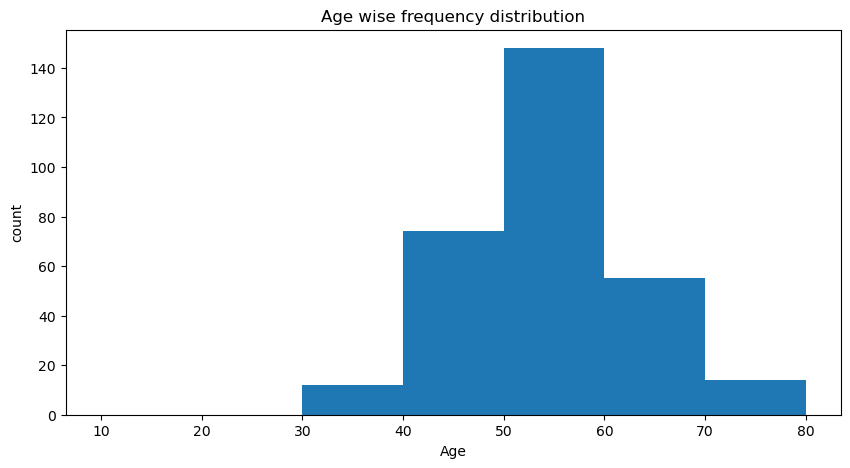

In [12]:
plt.hist(heart_df['age'], bins=[10, 20, 30, 40, 50, 60, 70, 80])
plt.title("Age wise frequency distribution")
plt.xlabel('Age')
plt.ylabel('count')
plt.show()

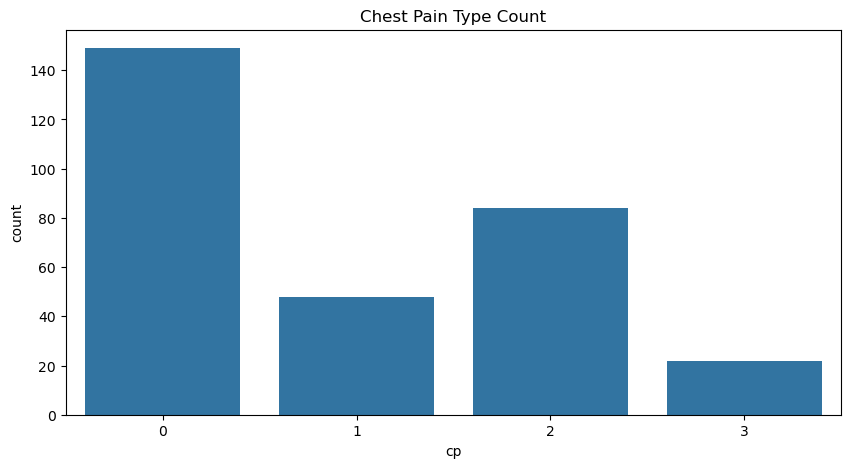

In [13]:
sns.countplot(data=heart_df, x='cp')
plt.title("Chest Pain Type Count")
plt.show()

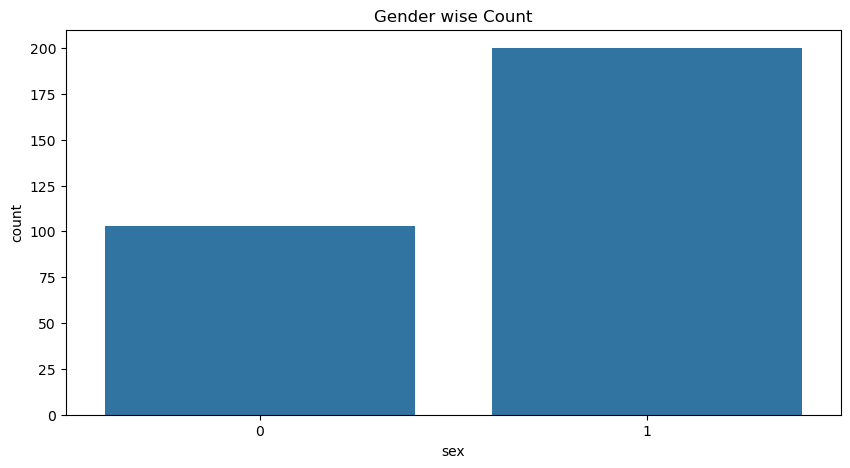

In [14]:
sns.countplot(data=heart_df, x='sex')
plt.title("Gender wise Count")
plt.show()

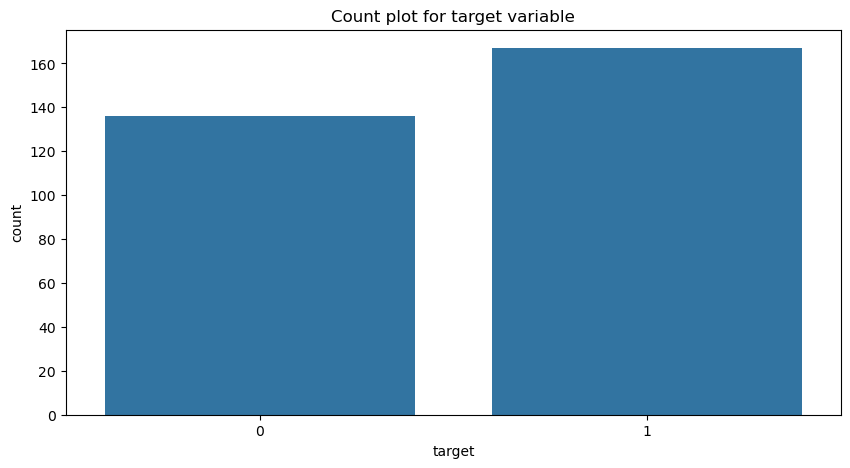

In [15]:
sns.countplot(data=heart_df, x='target')
plt.title("Count plot for target variable")
plt.show()

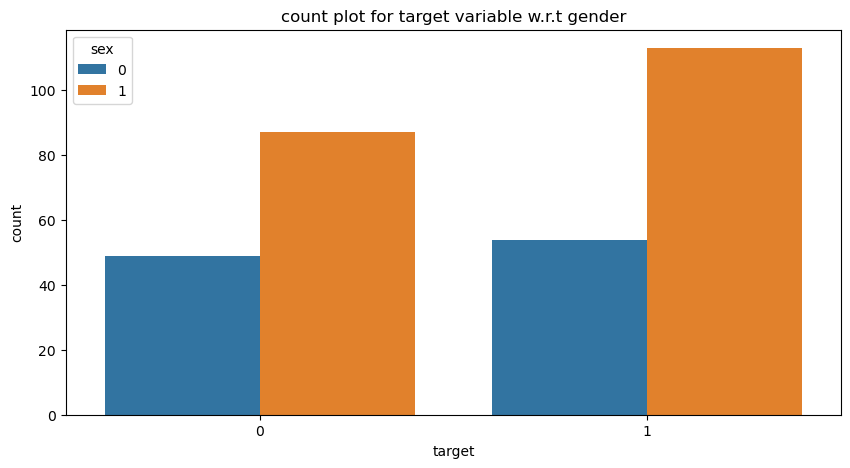

In [16]:
sns.countplot(data=heart_df, x='target', hue='sex')
plt.title("count plot for target variable w.r.t gender")
plt.show()

In [17]:
heart_df.duplicated().sum()

0

In [18]:
heart_df.drop_duplicates(inplace=True)

In [19]:
heart_df.shape

(303, 15)

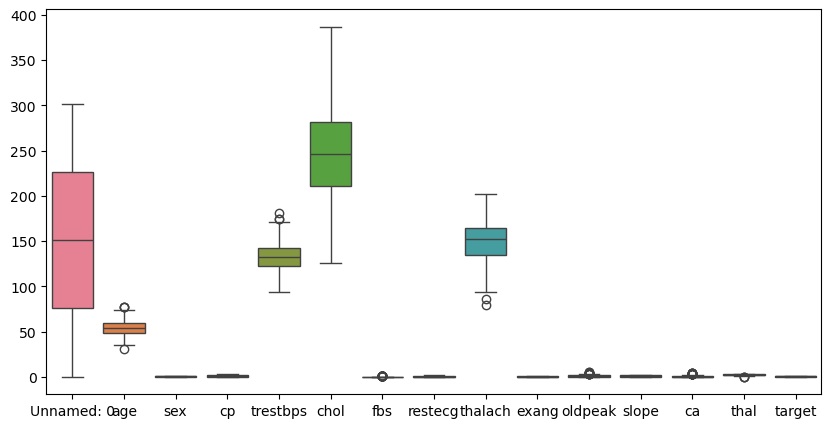

In [20]:
sns.boxplot(data=heart_df)
plt.show()

In [21]:
# Obtain the first quartile
q1 = heart_df.quantile(0.25)
# Obtain the third quartile
q3 = heart_df.quantile(0.75)
# Obtain the IQR
IQR = q3 - q1
print(IQR)

Unnamed: 0    151.0
age            11.0
sex             1.0
cp              2.0
trestbps       20.0
chol           70.5
fbs             0.0
restecg         1.0
thalach        30.0
exang           1.0
oldpeak         1.2
slope           2.0
ca              1.0
thal            1.0
target          1.0
dtype: float64


In [22]:
ul = q3 + 1.5 * IQR
ll = q1 - 1.5 * IQR

In [23]:
heart_df = heart_df[~((heart_df < ll) | (heart_df > ul)).any(axis=1)]
heart_df.shape

(220, 15)

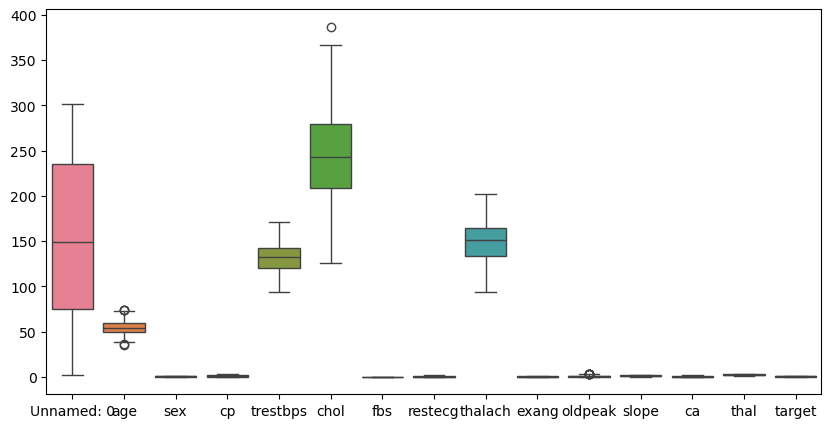

In [24]:
sns.boxplot(data=heart_df)
plt.show()

In [25]:
# Extracting features and target variables
X = heart_df.drop('target', axis=1)
y = heart_df['target']

In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [28]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

LogisticRegression()

In [29]:
logistic_model.score(X_train, y_train)

0.6647727272727273

In [30]:
y_predict = logistic_model.predict(X_test)

In [31]:
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score
confusion_matrix(y_test, y_predict)

array([[ 8, 16],
       [ 4, 16]], dtype=int64)

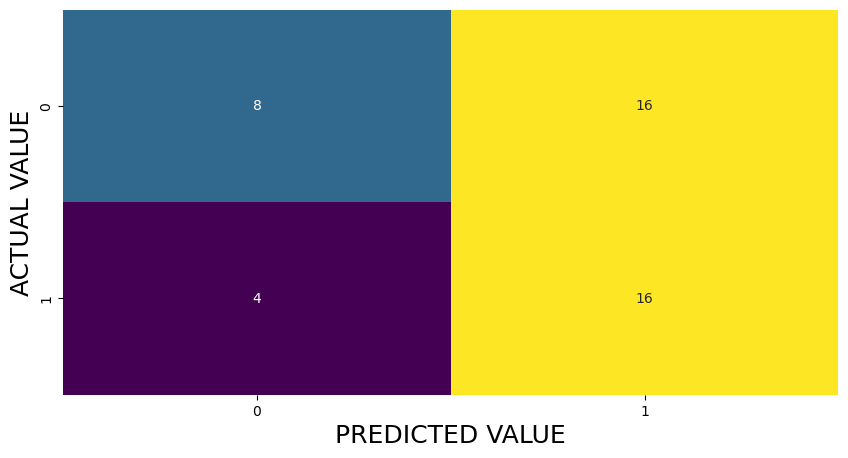

In [32]:
sns.heatmap(confusion_matrix(y_test, y_predict), annot=True, cbar=False, cmap='viridis')
plt.xlabel('PREDICTED VALUE', fontsize=18)
plt.ylabel('ACTUAL VALUE', fontsize=18)
plt.show()

In [33]:
accuracy_score(y_test, y_predict)

0.5454545454545454

In [34]:
precision_score(y_test, y_predict)

0.5

In [35]:
recall_score(y_test, y_predict)

0.8

In [36]:
f1_score(y_test, y_predict)

0.6153846153846154